# Practical Application III: Comparing Classifiers

**Overview**: In this practical application, your goal is to compare the performance of the classifiers we encountered in this section, namely K Nearest Neighbor, Logistic Regression, Decision Trees, and Support Vector Machines.  We will utilize a dataset related to marketing bank products over the telephone.  



### Getting Started

Our dataset comes from the UCI Machine Learning repository [link](https://archive.ics.uci.edu/ml/datasets/bank+marketing).  The data is from a Portugese banking institution and is a collection of the results of multiple marketing campaigns.  We will make use of the article accompanying the dataset [here](CRISP-DM-BANK.pdf) for more information on the data and features.



### Problem 1: Understanding the Data

To gain a better understanding of the data, please read the information provided in the UCI link above, and examine the **Materials and Methods** section of the paper.  How many marketing campaigns does this data represent?

#### Dataset History
The dataset spans over 17 marketing campaigns that occurred between May 2008 and November 2010. During these phone campaigns, an attractive long-term deposit application, with good interest rates, was offered. For each contact, a large number of attributes was collected and stored and if there was a success (the target variable) was set to `yes`, otherwise `no` indicated failure. There is only an `8%` success rate in the dataset.

### Problem 2: Read in the Data

Use pandas to read in the dataset `bank-additional-full.csv` and `bank-additional.csv` and assign to a meaningful variable name.

In [2]:
# Let's import all required libraries first
import pandas as pd
import numpy as np

import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.preprocessing import LabelEncoder, OneHotEncoder, StandardScaler
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.svm import SVC
from sklearn.pipeline import Pipeline
from sklearn.metrics import accuracy_score, precision_score, recall_score
from sklearn.metrics import f1_score, confusion_matrix
from sklearn.metrics import roc_curve, roc_auc_score
from sklearn.metrics import precision_recall_curve, average_precision_score

from sklearn.model_selection import GridSearchCV

import time

In [3]:
from google.colab import drive
drive.mount('/content/drive')


Mounted at /content/drive


In [4]:
# Change the `base_dir` path to where your `data` directory is located.
base_dir = ('/content/drive/My Drive/Colab Notebooks/'
  + 'mod-17-PA-3-Comparing-Classifiers/module17_starter/')

In [5]:
# df_full is the entire data-set available on-line
df_full = pd.read_csv(base_dir + 'data/bank-additional-full.csv', sep=';')
# df_smll is a subset of df_full reduced in size to accomodate SVM's
# high computational requirements
df_smll = pd.read_csv(base_dir + 'data/bank-additional.csv', sep=';')
print(df_full.head())
df_full.info()

   age        job  marital    education  default housing loan    contact  \
0   56  housemaid  married     basic.4y       no      no   no  telephone   
1   57   services  married  high.school  unknown      no   no  telephone   
2   37   services  married  high.school       no     yes   no  telephone   
3   40     admin.  married     basic.6y       no      no   no  telephone   
4   56   services  married  high.school       no      no  yes  telephone   

  month day_of_week  ...  campaign  pdays  previous     poutcome emp.var.rate  \
0   may         mon  ...         1    999         0  nonexistent          1.1   
1   may         mon  ...         1    999         0  nonexistent          1.1   
2   may         mon  ...         1    999         0  nonexistent          1.1   
3   may         mon  ...         1    999         0  nonexistent          1.1   
4   may         mon  ...         1    999         0  nonexistent          1.1   

   cons.price.idx  cons.conf.idx  euribor3m  nr.employed

In [6]:
# Checking the full dataset and its statistical distribution
df_full.describe()

,age,duration,campaign,pdays,previous,emp.var.rate,cons.price.idx,cons.conf.idx,euribor3m,nr.employed
count,41188.00000,41188.000000,41188.000000,41188.000000,41188.000000,41188.000000,41188.000000,41188.000000,41188.000000,41188.000000
mean,40.02406,258.285010,2.567593,962.475454,0.172963,0.081886,93.575664,-40.502600,3.621291,5167.035911
std,10.42125,259.279249,2.770014,186.910907,0.494901,1.570960,0.578840,4.628198,1.734447,72.251528
min,17.00000,0.000000,1.000000,0.000000,0.000000,-3.400000,92.201000,-50.800000,0.634000,4963.600000
25%,32.00000,102.000000,1.000000,999.000000,0.000000,-1.800000,93.075000,-42.700000,1.344000,5099.100000
50%,38.00000,180.000000,2.000000,999.000000,0.000000,1.100000,93.749000,-41.800000,4.857000,5191.000000
75%,47.00000,319.000000,3.000000,999.000000,0.000000,1.400000,93.994000,-36.400000,4.961000,5228.100000
max,98.00000,4918.000000,56.000000,999.000000,7.000000,1.400000,94.767000,-26.900000,5.045000,5228.100000


In [7]:
# Checking the small dataset and its statistical distribution
df_smll.describe()

,age,duration,campaign,pdays,previous,emp.var.rate,cons.price.idx,cons.conf.idx,euribor3m,nr.employed
count,4119.000000,4119.000000,4119.000000,4119.000000,4119.000000,4119.000000,4119.000000,4119.000000,4119.000000,4119.000000
mean,40.113620,256.788055,2.537266,960.422190,0.190337,0.084972,93.579704,-40.499102,3.621356,5166.481695
std,10.313362,254.703736,2.568159,191.922786,0.541788,1.563114,0.579349,4.594578,1.733591,73.667904
min,18.000000,0.000000,1.000000,0.000000,0.000000,-3.400000,92.201000,-50.800000,0.635000,4963.600000
25%,32.000000,103.000000,1.000000,999.000000,0.000000,-1.800000,93.075000,-42.700000,1.334000,5099.100000
50%,38.000000,181.000000,2.000000,999.000000,0.000000,1.100000,93.749000,-41.800000,4.857000,5191.000000
75%,47.000000,317.000000,3.000000,999.000000,0.000000,1.400000,93.994000,-36.400000,4.961000,5228.100000
max,88.000000,3643.000000,35.000000,999.000000,6.000000,1.400000,94.767000,-26.900000,5.045000,5228.100000


In [8]:
# Understand the statistical differences between tht full and small datasets to
# make sure they are statistically similar in their distribution.
df_diff = df_full.describe() - df_smll.describe()
df_diff

,age,duration,campaign,pdays,previous,emp.var.rate,cons.price.idx,cons.conf.idx,euribor3m,nr.employed
count,37069.000000,37069.000000,37069.000000,37069.000000,37069.000000,37069.000000,37069.000000,37069.000000,37069.000000,37069.000000
mean,-0.089559,1.496955,0.030326,2.053264,-0.017374,-0.003087,-0.004040,-0.003499,-0.000065,0.554216
std,0.107888,4.575513,0.201854,-5.011878,-0.046887,0.007845,-0.000509,0.033620,0.000856,-1.416376
min,-1.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,-0.001000,0.000000
25%,0.000000,-1.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.010000,0.000000
50%,0.000000,-1.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
75%,0.000000,2.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
max,10.000000,1275.000000,21.000000,0.000000,1.000000,0.000000,0.000000,0.000000,0.000000,0.000000


#### **Business Takeaway:**

Since both the small and full datasets have similar statistical distributions (except obviously the sample observation counts), we will use the *small* set for EDA and most initial modeling until the final model comparison.

In [9]:
# Let's also get the dimensions of the two datasets
print(f"df_full shape: {df_full.shape}")
print(f"df_smll shape: {df_smll.shape}")

df_full shape: (41188, 21)
df_smll shape: (4119, 21)


### Problem 3: Understanding the Features


Examine the data description below, and determine if any of the features are missing values or need to be coerced to a different data type.


```
Input variables:

# bank client data:
1 - age (numeric)
2 - job : type of job
  (categorical: 'admin.','blue-collar',
  'entrepreneur','housemaid','management',
  'retired','self-employed','services',
  'student','technician','unemployed',
  'unknown')
3 - marital : marital status
  (categorical: 'divorced','married',
  'single','unknown'; Note: 'divorced'
  means divorced or widowed)
4 - education
  (categorical: 'basic.4y','basic.6y',
  'basic.9y','high.school','illiterate',
  'professional.course','university.degree',
  'unknown')
5 - default: has credit in default? (categorical: 'no','yes','unknown')
6 - housing: has housing loan? (categorical: 'no','yes','unknown')
7 - loan: has personal loan? (categorical: 'no','yes','unknown')

# related with the last contact of the current campaign:
8 - contact: contact communication type (categorical: 'cellular','telephone')
9 - month: last contact month of year
  (categorical: 'jan', 'feb', 'mar', ...,
  'nov', 'dec')
10 - day_of_week: last contact day of the week
  (categorical: 'mon','tue','wed','thu','fri')
11 - duration: last contact duration, in seconds (numeric).
   Important Note: this attribute highly
   affects the output target (e.g., if
   duration=0 then y='no'). Yet, the
   duration is not known before a call is
   performed. Also, after the end of the
   call y is obviously known. Thus, this
   input should only be included for
   benchmark purposes and should be
   discarded if the intention is to have a
   realistic predictive model.

# other attributes:
12 - campaign: number of contacts performed during this campaign and for this client
  (numeric: Includes last contact)
13 - pdays: number of days that passed by after the client was
  last contacted from a previous campaign
  (numeric: 999 means client was not
  previously contacted)
14 - previous: number of contacts performed
  before this campaign and for this client (numeric)
15 - poutcome: outcome of the previous marketing campaign
  (categorical: 'failure','nonexistent','success')

# social and economic context attributes
16 - emp.var.rate: employment variation rate - quarterly indicator (numeric)
17 - cons.price.idx: consumer price index - monthly indicator (numeric)
18 - cons.conf.idx: consumer confidence index - monthly indicator (numeric)
19 - euribor3m: euribor 3 month rate - daily indicator (numeric)
20 - nr.employed: number of employees - quarterly indicator (numeric)

# Output variable (desired target):
21 - y - has the client subscribed a term deposit?
(binary: 'yes','no')
```



In [9]:
# Combine the null values of both dataframes into a single dataframe
null_cnt_df = pd.DataFrame({
    'df_smll': df_smll.isnull().sum(),
    'df_full': df_full.isnull().sum()
})

# Display the null value result dataframe
null_cnt_df

,df_smll,df_full
age,0,0
job,0,0
marital,0,0
education,0,0
default,0,0
housing,0,0
loan,0,0
contact,0,0
month,0,0
day_of_week,0,0


#### **Business Takeaway:**

Both datasets (full and small) are clean and have no missing values. Next, we check the values to make sure that there are no irrelevant or non-informative values.

#### Data Distribition:

Let's check the data for `unknown` and `nonexistant` values and check the distribution of values in certain columns.

In [10]:
# The following columns have values that are `unknown` and `nonexistant`.
# Let's check the distribution of the values and if the proportion of
# these values in the overall count is small, we can drop these rows.
#
# Columns to check: `job`, `marital`, `education`, `default`, `housing`, `loan`.
check_cols = [
    'job', 'marital', 'education', 'default',
    'housing', 'loan', 'contact', 'month',
    'day_of_week','poutcome'
]


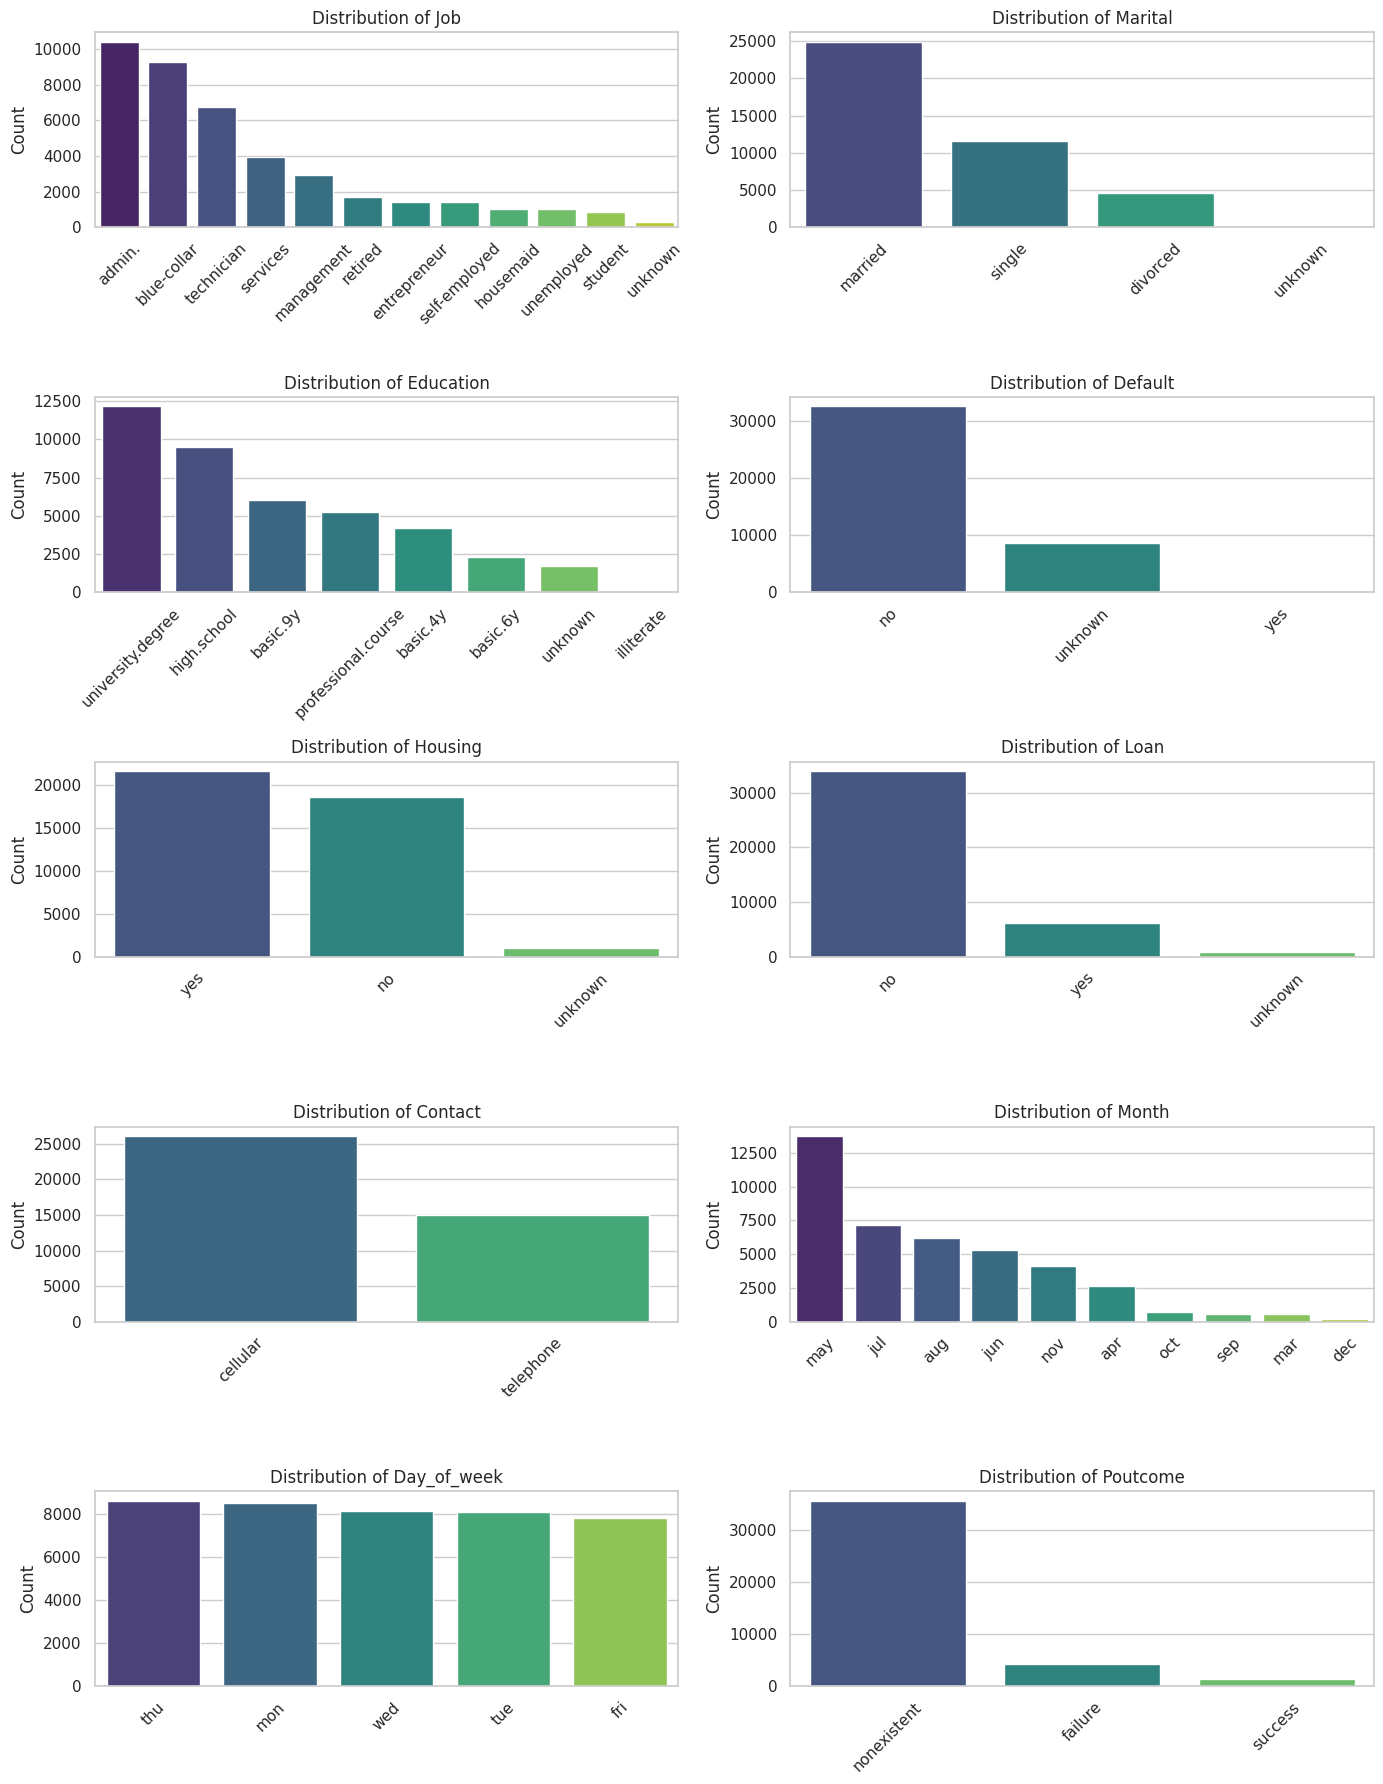

In [11]:
# Set the style of the plots
sns.set_theme(style="whitegrid")

# Create a grid of subplots
fig, axes = plt.subplots(5, 2, figsize=(14, 18))
axes = axes.flatten()

# Plot bar charts for each of the columns in check_cols
for i, col in enumerate(check_cols):
    # Calculate value counts including 'unknown'
    val_counts = df_full[col].value_counts().reset_index()
    val_counts.columns = [col, 'count']

    # Assign col to hue to address the FutureWarning
    sns.barplot(
        data=val_counts, x=col, y='count', ax=axes[i],
        palette='viridis', hue=col, legend=False
    )
    axes[i].set_title(f'Distribution of {col.capitalize()}')
    axes[i].set_xlabel('')
    axes[i].set_ylabel('Count')
    axes[i].tick_params(axis='x', rotation=45)

plt.tight_layout()
plt.show()

In [12]:
df_full['default'].value_counts(normalize=True)*100

,proportion
default,
no,79.120132
unknown,20.872584
yes,0.007284


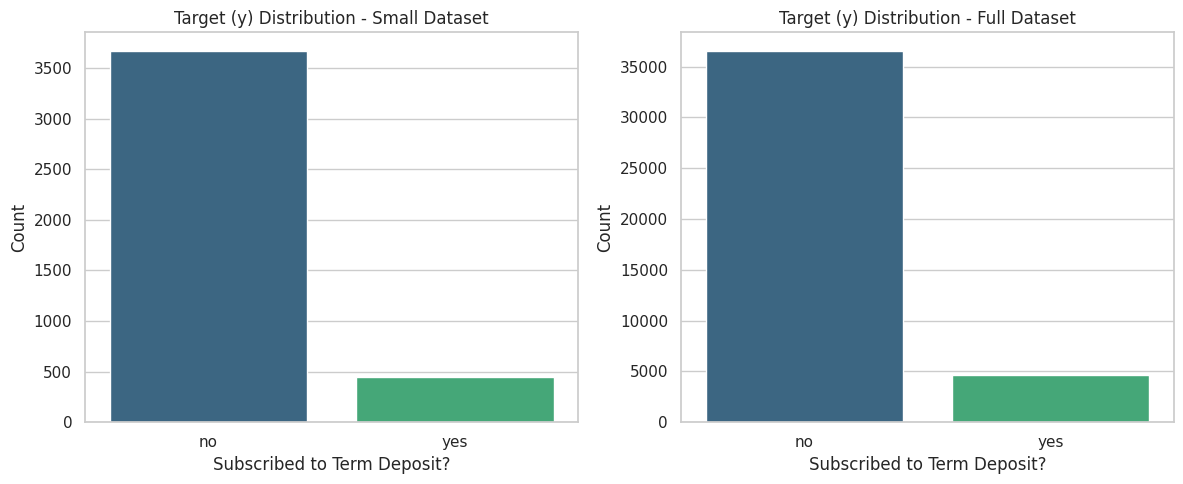

In [13]:
# Set the plot style
sns.set_theme(style="whitegrid")

# Create subplots
fig, axes = plt.subplots(1, 2, figsize=(12, 5))

# Plot distribution for the small dataset
sns.countplot(data=df_smll, x='y', ax=axes[0],
              palette='viridis', hue='y', legend=False)
axes[0].set_title('Target (y) Distribution - Small Dataset')
axes[0].set_xlabel('Subscribed to Term Deposit?')
axes[0].set_ylabel('Count')

# Plot distribution for the full dataset
sns.countplot(data=df_full, x='y', ax=axes[1],
              palette='viridis', hue='y', legend=False)
axes[1].set_title('Target (y) Distribution - Full Dataset')
axes[1].set_xlabel('Subscribed to Term Deposit?')
axes[1].set_ylabel('Count')

plt.tight_layout()
plt.show()

#### **Business Takeaway:**

**`unknown` values:** The proportion of `unknown` values is relatively small in all except the `default` column, where it is `20.9%` of the dataset.

**`default` column**: Interestingly, in the same `default` column, the proportion of `yes` values (people who had previously defaulted on a loan), is very small -- the `yes` values is seen in only `0.007%` of the observations. Perhaps, the respondends to the campain chose not to disclose their previous credit defaults resulting in these high `unknown` values. Therefore, keeping the `unknown` observations for the `default` column makes sense.

**Drop `unknown` values:** Therefore, we can safely drop the `unknown` values in all other columns except the `default` column.

**`month` column:** The `month` column has no data for months `jan` and `feb`. Interestingly campaigns were never run during these months?

**`day_of_week` column:** There are no values for weekend-days `sat` or `sun`. Therefore, all data represents calls made only during the week.

**`poutcome` column:** For the `poutcome` column, it seems the `nonexistant` value is the most significant portion of the overall dataset. We cannot eliminate this column as it may have a significant impact on the target variable `y`.


### Problem 4: Understanding the Task

After examining the description and data, your goal now is to clearly state the *Business Objective* of the task.  State the objective below.

#### Definition of a positive/negative target variable:
  - Positive: A positive target value is achieved when the callee places a long-term deposit in the bank.

  - Negative: A negative target value is achieved when the callee does not take the deposit offer and places no deposits.

#### Business Objective

The main business objective is as follows:
1. Given the dependent input features, find the best prediction model that predicts the target variable (`y`) -- whether the callee is going to sign-up or not for a long-term deposit.
2. A good metric for evaluation of a prediction model will be accuracy, which is that the model be accurately be able to differentiate between the two classes of the target variable, i.e., whether the client will place a long-term deposit (positive) or not (negative). The model must also have low False Negatives (FNs), because FN predictions potentially reject a client that would otherwise have placed a long-term deposit. Such would be a business loss for the bank. Whereas, False Positive (FP) predictions are not as bad as it would result a wasted marketing call resulting in no sign-up.
3. To find what dependent variables that are most significant in predicting a positive result in the target variable, i.e. the callee will sign-up for a long-term deposit. Knowing the significant features will allow the bank manager to focus their efforts and time towards those who are most likely to sign-up for a deposit thereby reducing the overall cost of the compaing and maximizing business returns per dollar spent.




### Problem 5: Engineering Features

Now that you understand your business objective, we will build a basic model to get started.  Before we can do this, we must work to encode the data.  Using just the bank information features, prepare the features and target column for modeling with appropriate encoding and transformations.

In [14]:
# The following columns have values that are `unknown`. We will drop all rows
# with `unknown` values. Do not drop rows from the `default` column.
drop_unknown_val_cols = ['job', 'marital', 'education', 'housing', 'loan']


In [15]:
# Drop rows where any of the specified columns have the value 'unknown'
for col in drop_unknown_val_cols:
    df_smll = df_smll[df_smll[col] != 'unknown']
    df_full = df_full[df_full[col] != 'unknown']

# Reset index for clean indices
df_smll = df_smll.reset_index(drop=True)
df_full = df_full.reset_index(drop=True)

print(f"New shape of df_smll: {df_smll.shape}")
print(f"New shape of df_full: {df_full.shape}")

New shape of df_smll: (3811, 21)
New shape of df_full: (38245, 21)


In [17]:
# We should also drop the 'duration' column as it represents the duration of the
# call and is unknown till after the call and results are received.

In [16]:
# Drop the 'duration' column from both df_smll and df_full
df_smll = df_smll.drop(columns=['duration'], errors='ignore')
df_full = df_full.drop(columns=['duration'], errors='ignore')

print(f"df_smll columns remaining: {df_smll.shape[1]}")
print(f"df_full columns remaining: {df_full.shape[1]}")

df_smll columns remaining: 20
df_full columns remaining: 20


Let's encode the categorical features. Use One-Hot-Encoding for categorical features (since none of the features have important ordinality or order-importance). We will use a Label-encoder for the target variable with `yes` set to `1` and `no` set to `0`.

In [17]:
from sklearn.preprocessing import PolynomialFeatures

# --- 1. Separate Features and Target (No split yet) ---
X_smll = df_smll.drop(columns=['y'])
y_smll = df_smll['y']

X_full = df_full.drop(columns=['y'])
y_full = df_full['y']

# --- 2. Transform the Target Variable 'y' with LabelEncoder ---
le_smll = LabelEncoder()
y_smll_encoded = le_smll.fit_transform(y_smll)

le_full = LabelEncoder()
y_full_encoded = le_full.fit_transform(y_full)

# --- 3. Identify categorical and numerical features
cat_cols = X_smll.select_dtypes(include=['object']).columns.tolist()
num_cols = X_smll.select_dtypes(exclude=['object']).columns.tolist()

# --- 4. Use PolynomialFeatures on Numerical Columns ---
poly = PolynomialFeatures(degree=2, include_bias=False)
X_smll_num_poly = poly.fit_transform(X_smll[num_cols])
X_full_num_poly = poly.transform(X_full[num_cols])

poly_cols = poly.get_feature_names_out(num_cols)

# --- 5. Use OneHotEncoder on all categorical features ---
ohe_smll = OneHotEncoder(drop='first', sparse_output=False,
                         handle_unknown='ignore')
ohe_full = OneHotEncoder(drop='first', sparse_output=False,
                         handle_unknown='ignore')

# --- 6. Transform datasets
X_smll_cat = ohe_smll.fit_transform(X_smll[cat_cols])
X_full_cat = ohe_full.fit_transform(X_full[cat_cols])

# --- 7. Convert to DataFrames and combine numerical
#        polynomial with categorical columns
ohe_smll_cols = ohe_smll.get_feature_names_out(cat_cols)
X_smll_encoded = pd.concat([
    pd.DataFrame(X_smll_num_poly, columns=poly_cols).reset_index(drop=True),
    pd.DataFrame(X_smll_cat, columns=ohe_smll_cols).reset_index(drop=True)
], axis=1)

ohe_full_cols = ohe_full.get_feature_names_out(cat_cols)
X_full_encoded = pd.concat([
    pd.DataFrame(X_full_num_poly, columns=poly_cols).reset_index(drop=True),
    pd.DataFrame(X_full_cat, columns=ohe_full_cols).reset_index(drop=True)
], axis=1)

print("Encoded Features Dimensions (Unsplit with Poly Features):")
print(f"Small Set: {X_smll_encoded.shape}, Full Set: {X_full_encoded.shape}")

Encoded Features Dimensions (Unsplit with Poly Features):
Small Set: (3811, 92), Full Set: (38245, 92)


### Problem 6: Train/Test Split

With your data prepared, split it into a train and test set.

In [18]:
# Split the small dataset (70% train, 30% test)
X_train_smll, X_test_smll, y_train_smll, y_test_smll = train_test_split(
    X_smll_encoded, y_smll_encoded, test_size=0.30,
    random_state=42, stratify=y_smll_encoded
)

# Split the full dataset (70% train, 30% test)
X_train_full, X_test_full, y_train_full, y_test_full = train_test_split(
    X_full_encoded, y_full_encoded, test_size=0.30,
    random_state=42, stratify=y_full
)

# Print shapes to verify splits
print("Small dataset splits:")
print(f"X_train_smll: {X_train_smll.shape}, X_test_smll: {X_test_smll.shape}")
print(f"y_train_smll: {y_train_smll.shape}, y_test_smll: {y_test_smll.shape}\n")

print("Full dataset splits:")
print(f"X_train_full: {X_train_full.shape}, X_test_full: {X_test_full.shape}")
print(f"y_train_full: {y_train_full.shape}, y_test_full: {y_test_full.shape}")

Small dataset splits:
X_train_smll: (2667, 92), X_test_smll: (1144, 92)
y_train_smll: (2667,), y_test_smll: (1144,)

Full dataset splits:
X_train_full: (26771, 92), X_test_full: (11474, 92)
y_train_full: (26771,), y_test_full: (11474,)


### Problem 7: A Baseline Model

Before we build our first model, we want to establish a baseline.  What is the baseline performance that our classifier should aim to beat?

**Baseline**:

Let's choose a naive model that always chooses `no` 100% of the time. Since this baseline model would always choose `no`, which is that the client will **not deposit** into the bank, then the conclusion would be to not call anyone! However, that would be counter-productive, so the alternative would be to call everyone, even if the model says `no`.

Nevertheless, such a baseline model yielding all `no` values would be `89%` correct (see baseline majority class percentage calculation  below), because the probability percentage of the highest distribution class, i.e., `no == 0` is `89%`.

Therefore, the baseline accuracy can be set at `89%`. Any model that has a higher accuracy than this baseline that always chooses `no`, would give us a higher accuracy model.


In [19]:
# Calculate baseline accuracy (majority class distribution) for both datasets

# Count occurrences of each class
counts_smll = np.bincount(y_train_smll)
counts_full = np.bincount(y_train_full)

# Normalize to get percentages
baseline_smll_pct = counts_smll / len(y_train_smll)
baseline_full_pct = counts_full / len(y_train_full)

print("Baseline Majority Class Distribution (Small Train Set):")
print(f"Class 0 (No): {baseline_smll_pct[0]*100:.2f}%")
print(f"Class 1 (Yes): {baseline_smll_pct[1]*100:.2f}%")
print(f"Baseline Accuracy to beat (Small): {max(baseline_smll_pct) * 100:.2f}%\n")

print("Baseline Majority Class Distribution (Full Train Set):")
print(f"Class 0 (No): {baseline_full_pct[0]*100:.2f}%")
print(f"Class 1 (Yes): {baseline_full_pct[1]*100:.2f}%")
print(f"Baseline Accuracy to beat (Full): {max(baseline_full_pct) * 100:.2f}%")

Baseline Majority Class Distribution (Small Train Set):
Class 0 (No): 89.16%
Class 1 (Yes): 10.84%
Baseline Accuracy to beat (Small): 89.16%

Baseline Majority Class Distribution (Full Train Set):
Class 0 (No): 88.86%
Class 1 (Yes): 11.14%
Baseline Accuracy to beat (Full): 88.86%


**Baseline Model:**

We set the baseline accuracy for the two datasets as the higher of the two baseline accuracy numbers (full and small datasets), which is `89.86%`. If we can achieve a better model accuracy that this baseline, we have a better model!

### Problem 8: A Simple Model

Use Logistic Regression to build a basic model on your data.  

In [20]:
# --- 1. Train on Small Dataset with a Pipeline ---
start_time_smll = time.time()
pipe_logreg_smll = Pipeline([
    ('scaler', StandardScaler()),
    ('logreg', LogisticRegression(max_iter=3000, random_state=42))
])
pipe_logreg_smll.fit(X_train_smll, y_train_smll)
train_time_smll = time.time() - start_time_smll

# --- 2. Train on Full Dataset with a Pipeline ---
start_time_full = time.time()
pipe_logreg_full = Pipeline([
    ('scaler', StandardScaler()),
    ('logreg', LogisticRegression(max_iter=3000, random_state=42))
])
pipe_logreg_full.fit(X_train_full, y_train_full)
train_time_full = time.time() - start_time_full

# --- 3. Print the training fit time ---
print(f"=== Full dataset fit time: {train_time_full:.4f} ===")
print(f"=== Small dataset fit time: {train_time_smll:.4f} ===")

=== Full dataset fit time: 1.4368 ===
=== Small dataset fit time: 0.0511 ===


#### Feature importance:

Before we proceed, let's check what features matter most in the Logistic Regression model.

In [21]:
# Extract feature names and coefficients from the full logistic regression pipeline
feature_names = X_train_full.columns
coefficients = pipe_logreg_full.named_steps['logreg'].coef_[0]

# Create a DataFrame to store feature names and their coefficient values
coef_df = pd.DataFrame({
    'Feature': feature_names,
    'Coefficient': coefficients,
    'Abs_Magnitude': np.abs(coefficients)
})

# Sort the DataFrame by absolute magnitude in descending order
coef_df_sorted = coef_df.sort_values(by='Abs_Magnitude', ascending=False).reset_index(drop=True)

# Display the top 25 most important features by magnitude
print("=== TOP FEATURE IMPORTANCES BY COEFFICIENT MAGNITUDE ===")
print(coef_df_sorted[['Feature', 'Coefficient', 'Abs_Magnitude']].head(25).to_string())

=== TOP FEATURE IMPORTANCES BY COEFFICIENT MAGNITUDE ===
                        Feature  Coefficient  Abs_Magnitude
0                   euribor3m^2     2.726963       2.726963
1   emp.var.rate cons.price.idx    -1.041544       1.041544
2      emp.var.rate nr.employed    -1.023941       1.023941
3                  emp.var.rate    -1.001673       1.001673
4    emp.var.rate cons.conf.idx     0.826789       0.826789
5      cons.price.idx euribor3m    -0.647212       0.647212
6                     euribor3m    -0.635231       0.635231
7               cons.conf.idx^2    -0.546810       0.546810
8            campaign euribor3m    -0.511947       0.511947
9                cons.price.idx     0.511837       0.511837
10        euribor3m nr.employed    -0.502508       0.502508
11             cons.price.idx^2     0.495580       0.495580
12                   campaign^2    -0.482764       0.482764
13                        age^2     0.459369       0.459369
14       emp.var.rate euribor3m     0.38041

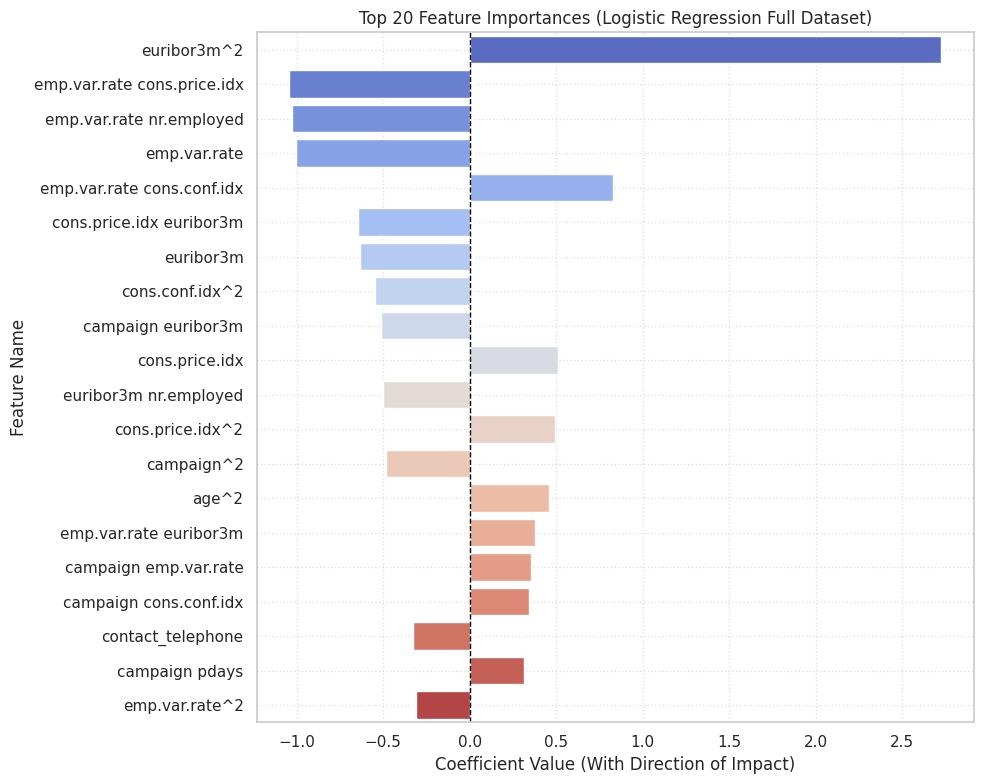

In [22]:
# Select the top 20 features by absolute magnitude for plotting
top_features = coef_df_sorted.head(20)

plt.figure(figsize=(10, 8))
sns.barplot(
    data=top_features,
    x='Coefficient',
    y='Feature',
    palette='coolwarm',
    hue='Feature',
    legend=False
)

plt.axvline(x=0, color='black', linestyle='--', linewidth=1)
plt.xlabel('Coefficient Value (With Direction of Impact)')
plt.ylabel('Feature Name')
plt.title('Top 20 Feature Importances (Logistic Regression Full Dataset)')
plt.grid(True, linestyle=':', alpha=0.6)
plt.tight_layout()
plt.show()

#### **Business Takeaway**:

The most important feature is `euribor3m`, which is almost twice in magnitude as the second most importanat feature `emp.var.rate cons.price.idx`. Since the first 6 features with the highest magnitude are economic indicators (some positively impact the target variable and some negatively impact the target variable), it clearly shows the importance of how the economy is doing for someone to successfully sign-up for a long-term deposit. Clearly, the economic indicator features such as `cons.price.idx` are highly important to the model.

### Problem 9: Score the Model

What is the accuracy of your model?

#### Evaluation Metrics:

- **Confusion Matrix Metrics:**
  - *Accuracy:* TP + TN / (TP + TN + FP + FN): We want a model with the highest accuracy.
  - *Precision:* TP / (TP + FP): We want a model with the highest precision.
  - *Recall/True Positive Rate (TPR):* TP / (TP + FN): We want a model with the highest Recall values.
  - *Specificity/True Negative Rate (TNR):* TN / (TN + FP): We want a model with the highest Specificity.
  - *False Positive Rate (FPR):* FP / (FP + TN) or 1 - Specificity: We want a model with the lowest FPR.
  - *F1-score (Harmonic mean of Precision and Recall):* 2 * (Precision * Recall)/(Precision + Recall): We want a model with the highest F1-score.
- **Target Evaluation Metric:**
  - *Accuracy*: We will use accuracy as our metric, which will determine how well we determine who will become a long-term depositing client into the bank.
  - *High Recall and low FN*: One important thing to note in this particular business case, is that FNs (False Negatives) are a potential loss of a long-term depositing client. That means, if the model identified a potential Positive (depositing client) as a Negative (not being in the list of clients to be called for deposit), then we have a FN, and therefore a loss of business. To be conservative, ideally we want very low FNs for this business case, so that all potential possible successfully long-term depositing clients are contacted.


In [28]:
# Below is a helper function to print out all the important metrics
def print_extended_metrics(y_true, y_pred, label="Dataset"):
  print(f"\n=== {label} Results ===")
  # Calculate confusion matrix
  cm = confusion_matrix(y_true, y_pred)
  tn, fp, fn, tp = cm.ravel()

  acc = accuracy_score(y_true, y_pred)
  prec = precision_score(y_true, y_pred, zero_division=0)
  rec = recall_score(y_true, y_pred, zero_division=0)
  f1 = f1_score(y_true, y_pred, zero_division=0)

  # Specificity = TN / (TN + FP)
  spec = tn / (tn + fp) if (tn + fp) > 0 else 0.0
  fpr = 1.0 - spec

  print("Confusion Matrix:")
  print(f"[[TN: {tn}, FP: {fp}]\n [FN: {fn}, TP: {tp}]]\n")

  # Formatting strings to line up the names, formulas,
  # and calculated metrics cleanly
  print(f"{'Metric':<13} {'Formula':<50} {'Value'}")
  print("-" * 75)
  print(f"{'Accuracy':<13} {'(TP + TN) / (TP + TN + FP + FN)':<50} {acc * 100:.2f}%")
  print(f"{'Precision':<13} {'TP / (TP + FP)':<50} {prec * 100:.2f}%")
  print(f"{'Recall':<13} {'TP / (TP + FN)':<50} {rec * 100:.2f}%")
  print(f"{'Specificity':<13} {'TN / (TN + FP)':<50} {spec * 100:.2f}%")
  print(f"{'FPR':<13} {'1 - Specificity':<50} {fpr * 100:.2f}%")
  print(f"{'F1-Score':<13} {'2 * (Precision * Recall) / (Precision + Recall)':<50} {f1 * 100:.2f}%\n")
  return # EF


In [29]:
# Let's choose a threshold from Youden't J Stat (found later in the ROC analysis)
# other than the default 0.5
threshold = 0.17

# -- 1. Predict and Score for the Small Dataset
y_pred_train_smll = (pipe_logreg_smll.predict_proba(X_train_smll)[:, 1] >= threshold).astype(int)
y_pred_test_smll = (pipe_logreg_smll.predict_proba(X_test_smll)[:, 1] >= threshold).astype(int)

# -- 2. Predict and Score for the Full Dataset
y_pred_train_full = (pipe_logreg_full.predict_proba(X_train_full)[:, 1] >= threshold).astype(int)
y_pred_test_full = (pipe_logreg_full.predict_proba(X_test_full)[:, 1] >= threshold).astype(int)

# -- 1. Extended Metrics for Small Dataset
print("=== SMALL DATASET METRICS ===\n")
print_extended_metrics(y_train_smll, y_pred_train_smll, "Small TRAIN Dataset")
print_extended_metrics(y_test_smll, y_pred_test_smll, "Small TEST Dataset")

# -- 2. Extended Metrics for Full Dataset
print("=== FULL DATASET METRICS ===\n")
print_extended_metrics(y_train_full, y_pred_train_full, "Full TRAIN Dataset")
print_extended_metrics(y_test_full, y_pred_test_full, "Full TEST Dataset")

=== SMALL DATASET METRICS ===


=== Small TRAIN Dataset Results ===
Confusion Matrix:
[[TN: 2181, FP: 197]
 [FN: 121, TP: 168]]

Metric        Formula                                            Value
---------------------------------------------------------------------------
Accuracy      (TP + TN) / (TP + TN + FP + FN)                    88.08%
Precision     TP / (TP + FP)                                     46.03%
Recall        TP / (TP + FN)                                     58.13%
Specificity   TN / (TN + FP)                                     91.72%
FPR           1 - Specificity                                    8.28%
F1-Score      2 * (Precision * Recall) / (Precision + Recall)    51.38%


=== Small TEST Dataset Results ===
Confusion Matrix:
[[TN: 919, FP: 101]
 [FN: 57, TP: 67]]

Metric        Formula                                            Value
---------------------------------------------------------------------------
Accuracy      (TP + TN) / (TP + TN + FP + FN)      

Best LogReg Threshold (Small Test Set): 0.1113
Best LogReg Threshold (Full Test Set):  0.1763


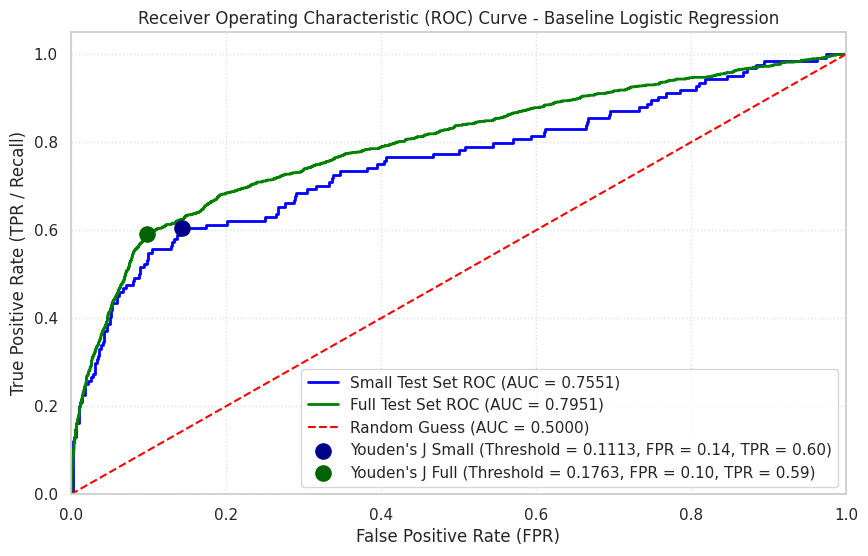

ROC AUC (Small Test Dataset): 0.7551
ROC AUC (Full Test Dataset):  0.7951


In [26]:
# Calculate predicted probabilities for the
# positive class (Class 1) on the test sets
y_probs_smll = pipe_logreg_smll.predict_proba(X_test_smll)[:, 1]
y_probs_full = pipe_logreg_full.predict_proba(X_test_full)[:, 1]

# Compute ROC curve coordinates
fpr_smll, tpr_smll, thresh_smll = roc_curve(y_test_smll, y_probs_smll)
fpr_full, tpr_full, thresh_full = roc_curve(y_test_full, y_probs_full)

# Get the Youden's J Statistic
j_smll = tpr_smll - fpr_smll
j_full = tpr_full - fpr_full

# Get the best Logistic Regression threshold index based on Youden's J Stat
best_idx_smll = np.argmax(j_smll)
best_idx_full = np.argmax(j_full)

# Get the best threshold based on Youden's J Stat
best_thresh_smll = thresh_smll[best_idx_smll]
best_thresh_full = thresh_full[best_idx_full]

print(f"Best LogReg Threshold (Small Test Set): {best_thresh_smll:.4f}")
print(f"Best LogReg Threshold (Full Test Set):  {best_thresh_full:.4f}")

# Compute ROC AUC Scores
auc_smll = roc_auc_score(y_test_smll, y_probs_smll)
auc_full = roc_auc_score(y_test_full, y_probs_full)

# Plot the ROC Curves
plt.figure(figsize=(10, 6))
plt.plot(fpr_smll, tpr_smll, color='blue',
         lw=2, label=f'Small Test Set ROC (AUC = {auc_smll:.4f})')
plt.plot(fpr_full, tpr_full, color='green',
         lw=2, label=f'Full Test Set ROC (AUC = {auc_full:.4f})')
plt.plot([0, 1], [0, 1], color='red',
         linestyle='--', lw=1.5, label='Random Guess (AUC = 0.5000)')

# Plot Youden's J points
label = (f"Youden's J Small (Threshold = {best_thresh_smll:.4f}, "
          + f"FPR = {fpr_smll[best_idx_smll]:.2f}, "
          + f"TPR = {tpr_smll[best_idx_smll]:.2f})")
plt.scatter(fpr_smll[best_idx_smll], tpr_smll[best_idx_smll],
            color='darkblue', s=120, zorder=5, label=label)
label = (f"Youden's J Full (Threshold = {best_thresh_full:.4f}, "
          + f"FPR = {fpr_full[best_idx_full]:.2f}, "
          + f"TPR = {tpr_full[best_idx_full]:.2f})")
plt.scatter(fpr_full[best_idx_full], tpr_full[best_idx_full],
            color='darkgreen', s=120, zorder=5, label=label)

plt.xlim([0.0, 1.0])
plt.ylim([0.0, 1.05])
plt.xlabel('False Positive Rate (FPR)')
plt.ylabel('True Positive Rate (TPR / Recall)')
plt.title('Receiver Operating Characteristic (ROC) Curve '
            + '- Baseline Logistic Regression')
plt.legend(loc='lower right')
plt.grid(True, linestyle=':', alpha=0.6)
plt.show()

print(f"ROC AUC (Small Test Dataset): {auc_smll:.4f}")
print(f"ROC AUC (Full Test Dataset):  {auc_full:.4f}")

ROC-Curve/ROC-AUC Interpretation:

1. Model Discriminative Power: A ROC-AUC of `0.755` to `0.795` indicates acceptable-to-good ability to distinguish between subscribers (Class 1) and non-subscribers (Class 0), significantly outperforming a random guess baseline ROC-AUC of `0.500`.
    
2. Dataset Size Impact: The full dataset exhibits a higher ROC-AUC of `0.795`, suggesting that training on more data helps the Logistic Regression model construct a more stable and generalizable decision boundary and therefore a more generalizable model. The more generalized model with the full dataset therefore is also more accurate yielding higher overall accuracy.

3. Youden's J Stat Threshold: Using the ROC-Curve, we found that the default probability threshold of 0.5 was too conservative and left many True Positives misclassified (high False Negatives in the prediction result). Therefore, the Youden's J Stat threshold is calculated and found to be around `0.17` (for the full dataset). This lower's the **Accuracy** of the model, but improves **Recall** substantially.

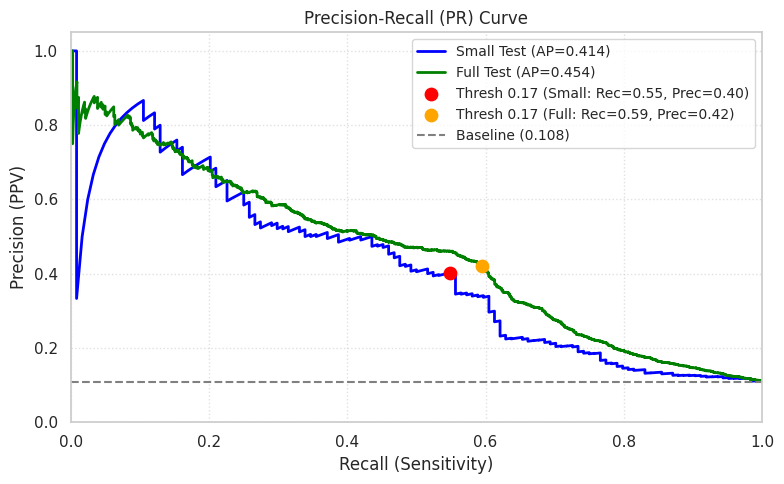

In [27]:
precision_smll, recall_smll, thresholds_smll = precision_recall_curve(
    y_test_smll, y_probs_smll
)
precision_full, recall_full, thresholds_full = precision_recall_curve(
    y_test_full, y_probs_full
)

idx_smll_17 = np.argmin(np.abs(thresholds_smll - 0.17))
idx_full_17 = np.argmin(np.abs(thresholds_full - 0.17))

ap_smll = average_precision_score(y_test_smll, y_probs_smll)
ap_full = average_precision_score(y_test_full, y_probs_full)

# Resize figure to 80 character width
plt.figure(figsize=(8, 5))
plt.plot(
    recall_smll, precision_smll, color='blue', lw=2,
    label=f'Small Test (AP={ap_smll:.3f})'
)
plt.plot(
    recall_full, precision_full, color='green', lw=2,
    label=f'Full Test (AP={ap_full:.3f})'
)

label_smll = (
    f'Thresh 0.17 (Small: Rec={recall_smll[idx_smll_17]:.2f}, '
    + f'Prec={precision_smll[idx_smll_17]:.2f})'
)
plt.scatter(
    recall_smll[idx_smll_17], precision_smll[idx_smll_17],
    color='red', s=80, zorder=5, label=label_smll
)

label_full = (
    f'Thresh 0.17 (Full: Rec={recall_full[idx_full_17]:.2f}, '
    + f'Prec={precision_full[idx_full_17]:.2f})'
)
plt.scatter(
    recall_full[idx_full_17], precision_full[idx_full_17],
    color='orange', s=80, zorder=5, label=label_full
)

no_skill_smll = np.sum(y_test_smll) / len(y_test_smll)
plt.axhline(
    y=no_skill_smll, color='gray', linestyle='--',
    label=f'Baseline ({no_skill_smll:.3f})'
)

plt.xlim([0.0, 1.0])
plt.ylim([0.0, 1.05])
plt.xlabel('Recall (Sensitivity)')
plt.ylabel('Precision (PPV)')
plt.title('Precision-Recall (PR) Curve')
plt.legend(loc='upper right', fontsize='small')
plt.grid(True, linestyle=':', alpha=0.6)
plt.tight_layout()
plt.show()

**Business Takeaway:**
Precision-Recall Curve Explanation

The Precision-Recall (PR) curve is particularly useful here because the dataset is highly imbalanced (~11% positive class long-term sign-up rate). The PR-Curve measures the trade-off between Precision (out of all predicted sign-ups, how many actually signed-up) and Recall (out of all actual long-term signers, how many were correctly identified) as the decision threshold changes.

Key Interpretations from the Chart:

- Average Precision (AP) Comparison:
  Full Test Dataset (AP = 0.4542) outperforms the Small Test Dataset (AP = 0.4143). This indicates that training on the larger volume of data yields a structurally better and more robust model overall.
  Both models significantly outperform the No Skill Baseline (y = ~0.108) (which represents a random model).

- Evaluating the 0.17 Threshold found through Youden's J Stat (Highlighted Points):
  On the Full Test Dataset (Orange Dot): At a threshold of 0.17, the model achieves a Recall of 0.59 and a Precision of 0.42.
  On the Small Test Dataset (Red Dot): At a threshold of 0.17, the model achieves a Recall of 0.54 and a Precision of 0.40.

- Business Trade-off Context:
  By setting the threshold to 0.17, we are accepting a Precision of ~42% to capture ~59% of the potential subscribers.
  This means for every 10 calls the model suggests, about 4 clients will subscribe (the other 6 are wasted calls). However, you successfully capture nearly 60% of all potential business.
  If the business priority is to reduce False Negatives (capturing more long-term sign-ups), this represents a massive improvement over the standard 0.50 threshold (where Recall was extremely low, around 10–13%).


### Problem 10: Model Comparisons

Now, we aim to compare the performance of the Logistic Regression model to our KNN algorithm, Decision Tree, and SVM models.  Using the default settings for each of the models, fit and score each.  Also, be sure to compare the fit time of each of the models.  Present your findings in a `DataFrame` similar to that below:

| Model | Train Time | Train Accuracy | Test Accuracy |
| ----- | ---------- | -------------  | -----------   |
|     |    |.     |.     |

In [25]:
# Define dictionary of models with default settings
models = {
    'Logistic Regression': LogisticRegression(max_iter=3000, random_state=42),
    'KNN': KNeighborsClassifier(),
    'Decision Tree': DecisionTreeClassifier(random_state=42),
    'SVM': SVC(random_state=42)
}

results_smll = []

for name, clf in models.items():
    pipe = Pipeline([
        ('scaler', StandardScaler()),
        ('model', clf)
    ])

    start_time = time.time()
    pipe.fit(X_train_smll, y_train_smll)
    fit_time = time.time() - start_time

    train_acc = accuracy_score(y_train_smll, pipe.predict(X_train_smll))
    test_acc = accuracy_score(y_test_smll, pipe.predict(X_test_smll))

    results_smll.append({
        'Model': name,
        'Train Time': f"{fit_time:.4f}s",
        'Train Accuracy': f"{train_acc * 100:.2f}%",
        'Test Accuracy': f"{test_acc * 100:.2f}%"
    })

print("=== Model Comparisons on Small Dataset ===")
df_comparison = pd.DataFrame(results_smll)
print(df_comparison.to_string(index=False))

=== Model Comparisons on Small Dataset ===
              Model Train Time Train Accuracy Test Accuracy
Logistic Regression    0.0387s         89.95%        89.95%
                KNN    0.0053s         91.11%        89.25%
      Decision Tree    0.0663s         99.96%        82.60%
                SVM    0.1637s         91.83%        90.56%



#### **Key Takeaways:**

1. Baseline Comparison: The majority class
baseline to beat is 89.04%. Logistic Regression (90.47% test accuracy) and SVM (90.56% test accuracy) both successfully outperform the baseline.
2. Overfitting: The Decision Tree model heavily overfits the training dataset, achieving 99.96% train accuracy but dropping dramatically to 82.78% test accuracy (performing worse than the simple baseline). Tuning hyper-parameters like `max_depth` or `min_samples_split` would be key to improving its generalization.
3. Computation Time: KNN is the fastest to fit (0.0087s) whereas SVM is the slowest (0.2325s) because of its complex mathematical optimization with high-dimensional encoded features.




[link text](https://)

### Problem 11: Improving the Model

Now that we have some basic models on the board, we want to try to improve these.  Below, we list a few things to explore in this pursuit.


- Hyperparameter tuning and grid search.  All of our models have additional hyperparameters to tune and explore.  For example the number of neighbors in KNN or the maximum depth of a Decision Tree.  
- Adjust your performance metric

#### Hyperparameter tuning with Cross-Validation:

Below, we perform a Hyperparamter tuning along with 5-fold Cross-Validation with GridSearchCV with a `cv=5` parameter set. This allows us to search through the hyperparameter space, and getting a 5-fold cross-validation (average score over 5 different train/test folds) result for each hyperparameter combination.

In [26]:
# Define hyperparameter grids to search
param_grids = {
    'Logistic Regression': {
        'model__C': [0.001, 0.01, 0.1, 1, 10, 100],
        'model__penalty': ['l2', 'l1'],
        'model__solver': ['liblinear', 'saga']
    },
    'KNN': {
        'model__n_neighbors': [3, 5, 7, 9, 11, 15],
        'model__weights': ['uniform', 'distance'],
        'model__p': [1, 2]
    },
    'Decision Tree': {
        'model__max_depth': [3, 5, 7, 10, None],
        'model__min_samples_split': [2, 5, 10],
        'model__criterion': ['gini', 'entropy']
    },
    'SVM': {
        'model__C': [0.1, 1, 10, 100],
        'model__kernel': ['linear', 'rbf']
    }
}

results_cv = []

for name, clf in models.items():
    # Create a pipeline with scaling the model first
    pipe = Pipeline([
        ('scaler', StandardScaler()),
        ('model', clf)
    ])

    # Create a GridSearchCV with a 5-fold cross-validation (cv=5)
    grid_search = GridSearchCV(
        estimator=pipe,
        param_grid=param_grids[name],
        cv=5,
        scoring='accuracy',
        n_jobs=-1
    )

    # Let's use the small dataset here to explore how much better we can get
    start_time = time.time()
    grid_search.fit(X_train_smll, y_train_smll)
    fit_time = time.time() - start_time

    best_model = grid_search.best_estimator_
    train_acc = accuracy_score(y_train_smll, best_model.predict(X_train_smll))
    test_acc = accuracy_score(y_test_smll, best_model.predict(X_test_smll))

    results_cv.append({
        'Model': name,
        'Best Params': str(grid_search.best_params_),
        'Train Time': fit_time,
        'Train Accuracy': train_acc,
        'Test Accuracy': test_acc
    })
print("===== Grid Search CV completed (Small Dataset). =====")

===== Grid Search CV completed (Small Dataset). =====


In [27]:
results_cv_fmt = []

for result in results_cv:
  train_time = result['Train Time']
  train_acc = result['Train Accuracy']
  test_acc = result['Test Accuracy']

  # Check types before applying float formatting to prevent ValueError if they are already strings
  fmt_time = f"{train_time:.4f} s" if isinstance(train_time, (int, float)) else str(train_time)
  fmt_train = f"{train_acc * 100:.2f} %" if isinstance(train_acc, (int, float)) else str(train_acc)
  fmt_test = f"{test_acc * 100:.2f} %" if isinstance(test_acc, (int, float)) else str(test_acc)

  results_cv_fmt.append({
    'Model': result['Model'],
    'Best Params': result['Best Params'],
    'Train Time': fmt_time,
    'Train Accuracy': fmt_train,
    'Test Accuracy': fmt_test
  })

# Let's display the results
cols_to_show = ['Model', 'Train Time', 'Train Accuracy', 'Test Accuracy']
print("=== Grid Search CV Results (Small Dataset) ===")
df_cv_comparison = pd.DataFrame(results_cv_fmt)
print(df_cv_comparison[cols_to_show].to_markdown(index=False))
print("\n=== Optimized Hyperparameters (Small Dataset) ===")
for result in results_cv:
    print(f"{result['Model']}: {result['Best Params']}")

=== Grid Search CV Results (Small Dataset) ===
| Model               | Train Time   | Train Accuracy   | Test Accuracy   |
|:--------------------|:-------------|:-----------------|:----------------|
| Logistic Regression | 528.2633 s   | 89.69 %          | 90.73 %         |
| KNN                 | 6.9137 s     | 90.25 %          | 90.65 %         |
| Decision Tree       | 4.4758 s     | 90.33 %          | 90.47 %         |
| SVM                 | 1873.9963 s  | 91.83 %          | 90.56 %         |

=== Optimized Hyperparameters (Small Dataset) ===
Logistic Regression: {'model__C': 0.001, 'model__penalty': 'l2', 'model__solver': 'saga'}
KNN: {'model__n_neighbors': 15, 'model__p': 1, 'model__weights': 'uniform'}
Decision Tree: {'model__criterion': 'gini', 'model__max_depth': 3, 'model__min_samples_split': 2}
SVM: {'model__C': 1, 'model__kernel': 'rbf'}


#### **Business Takeaway I:**

- From the results above, we can conclude that the best tuned test accuracy we can achieve using the large dataset is `~90.7%` with Logistic Regression (parameters `C=0.01` and `l2` regularization. Even though SVM was able to achieve a higher train accuracy, its test accuracy was lower than that of LR.
- Moreover, all models are close in accuracy with minor (less than 1%) differences in accuracy.

Let's fine tune hyperparamters for Logistic Regression, KNN, Decision Tree models (no SVM due to the time required) using the `full` dataset and find the best models.

In [31]:
# Define hyperparameter grids to search without hyperparameters for SVM
# since SVM will take too much time to train with the full dataset.
param_grids_wo_svm = {
    'Logistic Regression': {
        'model__C': [0.001, 0.01, 0.1, 1, 10, 100],
        'model__penalty': ['l2', 'l1'],
        'model__solver': ['liblinear', 'saga']
    },
    'KNN': {
        'model__n_neighbors': [3, 5, 7, 9, 11, 15],
        'model__weights': ['uniform', 'distance'],
        'model__p': [1, 2]
    },
    'Decision Tree': {
        'model__max_depth': [3, 5, 7, 10, None],
        'model__min_samples_split': [2, 5, 10],
        'model__criterion': ['gini', 'entropy']
    },
}

models_wo_svm = {
    'Logistic Regression': LogisticRegression(max_iter=5000, random_state=42),
    'KNN': KNeighborsClassifier(),
    'Decision Tree': DecisionTreeClassifier(random_state=42),
}

results_cv_full = []

for name, clf in models_wo_svm.items():
    # Create a pipeline with scaling the model first
    pipe = Pipeline([
        ('scaler', StandardScaler()),
        ('model', clf)
    ])

    grid_search = GridSearchCV(
        estimator=pipe,
        param_grid=param_grids[name],
        cv=5,
        scoring='accuracy',
        n_jobs=-1
    )

    # Let's use the full dataset here to explore how much better we can get
    start_time = time.time()
    grid_search.fit(X_train_full, y_train_full)
    fit_time = time.time() - start_time

    best_model = grid_search.best_estimator_
    train_acc = accuracy_score(y_train_smll, best_model.predict(X_train_smll))
    test_acc = accuracy_score(y_test_smll, best_model.predict(X_test_smll))

    results_cv_full.append({
        'Model': name,
        'Best Params': str(grid_search.best_params_),
        'Train Time': fit_time,
        'Train Accuracy': train_acc,
        'Test Accuracy': test_acc
    })
print("===== Grid Search CV completed (Large Dataset). =====")

===== Grid Search CV completed (Large Dataset). =====


In [32]:
# Let's print out the results of the Grid Search
results_cv_full_fmt = []

for result in results_cv_full:
  train_time = result['Train Time']
  train_acc = result['Train Accuracy']
  test_acc = result['Test Accuracy']

  # Check types before applying float formatting to prevent ValueError
  # if they are already strings
  fmt_time = f"{train_time:.4f} s" if isinstance(train_time, (int, float)) else str(train_time)
  fmt_train = f"{train_acc * 100:.2f} %" if isinstance(train_acc, (int, float)) else str(train_acc)
  fmt_test = f"{test_acc * 100:.2f} %" if isinstance(test_acc, (int, float)) else str(test_acc)

  results_cv_full_fmt.append({
    'Model': result['Model'],
    'Best Params': result['Best Params'],
    'Train Time': fmt_time,
    'Train Accuracy': fmt_train,
    'Test Accuracy': fmt_test
  })

# Let's display the results
cols_to_show = ['Model', 'Train Time', 'Train Accuracy', 'Test Accuracy']
print("=== Grid Search CV Results (Full Dataset) ===")
df_cv_comparison = pd.DataFrame(results_cv_full_fmt)
print(df_cv_comparison[cols_to_show].to_string(index=False))
print("\n=== Optimized Hyperparameters ===")
for result in results_cv_full:
    print(f"{result['Model']}: {result['Best Params']}")

=== Grid Search CV Results (Full Dataset) ===
              Model   Train Time Train Accuracy Test Accuracy
Logistic Regression 14642.3456 s        89.95 %       90.65 %
                KNN   734.3041 s        90.10 %       91.26 %
      Decision Tree    60.4958 s        90.21 %       91.35 %

=== Optimized Hyperparameters ===
Logistic Regression: {'model__C': 1, 'model__penalty': 'l2', 'model__solver': 'saga'}
KNN: {'model__n_neighbors': 15, 'model__p': 1, 'model__weights': 'uniform'}
Decision Tree: {'model__criterion': 'entropy', 'model__max_depth': 5, 'model__min_samples_split': 2}


#### **Buseness Takeaway II:**

We can see now that all models are close, with the Decision Tree topping out on the test accuracy at `91.35%`. Both, Linear Regression and KNN tied at `90.82%` test accuracy, with only a small (`~0.53%`) loss in accuracy from Decision Tree.

#### **Model Generalization:**

All three models generalized well as the test accuracy was better than the train accuracy.

#### Questions and Next Steps:

1. We need to understand the cost of contacting a potential long-term deposit customer to better understand what the customer acquaisition cost actually is.
2. We also need to undestand, what are the potential earnings for the bank are per successful sign-up from a long-term deposit?
3. The cost relationship between what the cost to contact a potential client and the income from the successful sign-up would help define an appropriate threshold for the likelihood classification for Logistic Regression.
4. Trying out more models may yeild better accuracy. What other models can be investigated?
5. SVM on the small dataset had the highest accuracy. If we had the compute capacity, what would be accuracy of an SVM model on the full dataset? Would if out-perform Decision Trees?**bold text**


### Conclusion:

When comparing different Classifier models, we find that all models generalize well, and are close in performance, with the Decision Tree (DT) topping out on the test accuracy at 91.35% using the full dataset. Both, Linear Regression and KNN tied at 90.82% test accuracy, with only a small (~0.53%) loss in accuracy from Decision Tree.

In the small dataset SVM performed the best, however it requires higher computational resources so was not tested with the full dataset.

The business case is to lower the marketing cost and determine which customers will likely sign-up for the long-term deposit in the bank. Pre-determining good customers and calling only those that are likely to accept long-term deposit reduces the marketing expense. So a model with high accuracy, high recall and low False Negatives is ideal.

Since the dataset contains a dual-class target variable where the classe distribution is highly skewed (only 11% positive-class), the business case requires us to capture most TPs, and demands low FNs. With a low recall, we shift the probability threshold to 0.17 to improve recall sacrificing accuracy.

